# 01 — SpaceX Launch Data Exploration

## Objective
Explore the SpaceX Falcon 9 launch dataset, understand its structure, summarize key variables, and investigate how launch outcomes (`Class`) relate to flight number, payload mass, orbit, and launch site.

### Learning goals
- Load and inspect a CSV dataset with pandas.
- Summarize numeric and categorical variables.
- Compare successful and unsuccessful launches.
- Create exploratory visualizations with Matplotlib and Seaborn.
- Describe patterns without treating correlation as proof of causation.

> **Dataset required:** `data/raw/dataset_falcon9.csv`  
> Place the original course dataset at this path relative to the project root.

## 1. Import libraries

In [28]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset
The path below assumes the notebook is run from the project root (`data-science-learning/`). If you launch Jupyter from another working directory, adjust `DATA_PATH` accordingly.

In [29]:
DATA_PATH = Path("../data/raw/dataset_falcon9.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Copy dataset_falcon9.csv into the project's data/raw/ directory."
    )

df = pd.read_csv(DATA_PATH)
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


## 3. Inspect the data

In [30]:
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
df.info()

Rows: 90
Columns: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 18 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   FlightNumber    90 non-null     int64  
 1   Date            90 non-null     object 
 2   BoosterVersion  90 non-null     object 
 3   PayloadMass     90 non-null     float64
 4   Orbit           90 non-null     object 
 5   LaunchSite      90 non-null     object 
 6   Outcome         90 non-null     object 
 7   Flights         90 non-null     int64  
 8   GridFins        90 non-null     bool   
 9   Reused          90 non-null     bool   
 10  Legs            90 non-null     bool   
 11  LandingPad      64 non-null     object 
 12  Block           90 non-null     float64
 13  ReusedCount     90 non-null     int64  
 14  Serial          90 non-null     object 
 15  Longitude       90 non-null     float64
 16  Latitude        90 non-null     float64
 17  Class           

In [31]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlightNumber,90.0,NaN,NaN,NaN,45.5,26.124701,1.0,23.25,45.5,67.75,90.0
Date,90,90,2010-06-04,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BoosterVersion,90,1,Falcon 9,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PayloadMass,90.0,NaN,NaN,NaN,6104.959412,4694.67172,350.0,2510.75,4701.5,8912.75,15600.0
Orbit,90,11,GTO,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LaunchSite,90,3,CCAFS SLC 40,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outcome,90,8,True ASDS,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flights,90.0,NaN,NaN,NaN,1.788889,1.213172,1.0,1.0,1.0,2.0,6.0
GridFins,90,2,True,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reused,90,2,False,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0].to_frame("missing_values")

,missing_values
LandingPad,26


## 4. Dates, booster versions, and payload mass

These cells inspect several fields from the course dataset. `PayloadMass` represents the payload mass in kilograms where values are available.

In [33]:
df[["Date", "BoosterVersion", "PayloadMass"]].head()

,Date,BoosterVersion,PayloadMass
0,2010-06-04,Falcon 9,6104.959412
1,2012-05-22,Falcon 9,525.000000
2,2013-03-01,Falcon 9,677.000000
3,2013-09-29,Falcon 9,500.000000
4,2013-12-03,Falcon 9,3170.000000


In [34]:
df["BoosterVersion"].value_counts(dropna=False)

BoosterVersion
Falcon 9    90
Name: count, dtype: int64

In [35]:
payload_summary = df["PayloadMass"].describe()
payload_summary

count       90.000000
mean      6104.959412
std       4694.671720
min        350.000000
25%       2510.750000
50%       4701.500000
75%       8912.750000
max      15600.000000
Name: PayloadMass, dtype: float64

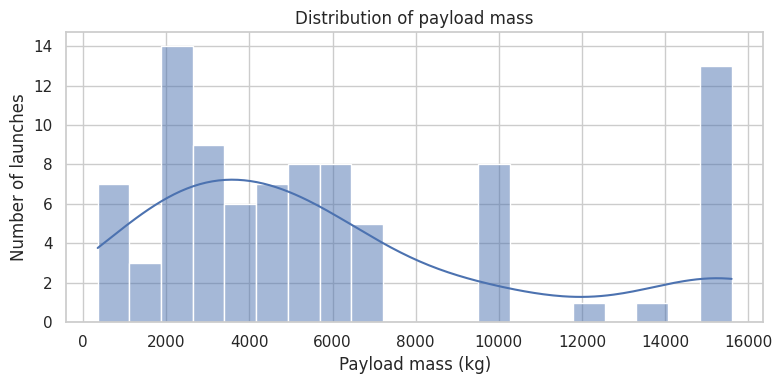

In [36]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df, x="PayloadMass", bins=20, kde=True, ax=ax)
ax.set(title="Distribution of payload mass", xlabel="Payload mass (kg)", ylabel="Number of launches")
plt.tight_layout()
plt.show()

## 5. Explore orbit types
An orbit is the trajectory followed by a spacecraft around a celestial body. This notebook uses the orbit labels exactly as they appear in the dataset.

In [37]:
orbit_counts = df["Orbit"].value_counts(dropna=False)
orbit_counts

Orbit
GTO      27
ISS      21
VLEO     14
PO        9
LEO       7
SSO       5
MEO       3
HEO       1
ES-L1     1
SO        1
GEO       1
Name: count, dtype: int64

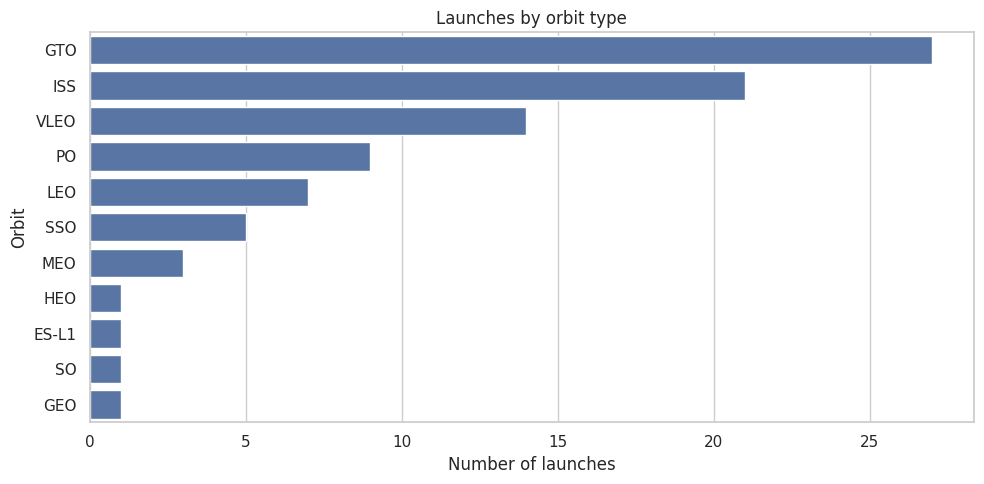

In [38]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, y="Orbit", order=df["Orbit"].value_counts().index, ax=ax)
ax.set(title="Launches by orbit type", xlabel="Number of launches", ylabel="Orbit")
plt.tight_layout()
plt.show()

## 6. Compare successful and unsuccessful launches
In this dataset, `Class == 1` is treated as a successful launch and other values as unsuccessful, following the original notebook's convention. Confirm the coding in the dataset documentation if you use a different version.

In [39]:
if "Class" not in df.columns:
    raise KeyError("Expected a 'Class' column in the dataset.")

df["Class"].value_counts(dropna=False).sort_index()

Class
0    30
1    60
Name: count, dtype: int64

In [40]:
df_success = df[df["Class"] == 1].copy()
df_fail = df[df["Class"] != 1].copy()

print(f"Successful launches: {len(df_success)}")
print(f"Other launch outcomes: {len(df_fail)}")

Successful launches: 60
Other launch outcomes: 30


In [41]:
success_by_orbit = df_success["Orbit"].value_counts().rename("successful")
failure_by_orbit = df_fail["Orbit"].value_counts().rename("other_outcomes")
pd.concat([success_by_orbit, failure_by_orbit], axis=1).fillna(0).astype(int)

,successful,other_outcomes
Orbit,,
GTO,14,13
ISS,13,8
VLEO,12,2
PO,6,3
LEO,5,2
SSO,5,0
MEO,2,1
ES-L1,1,0
HEO,1,0


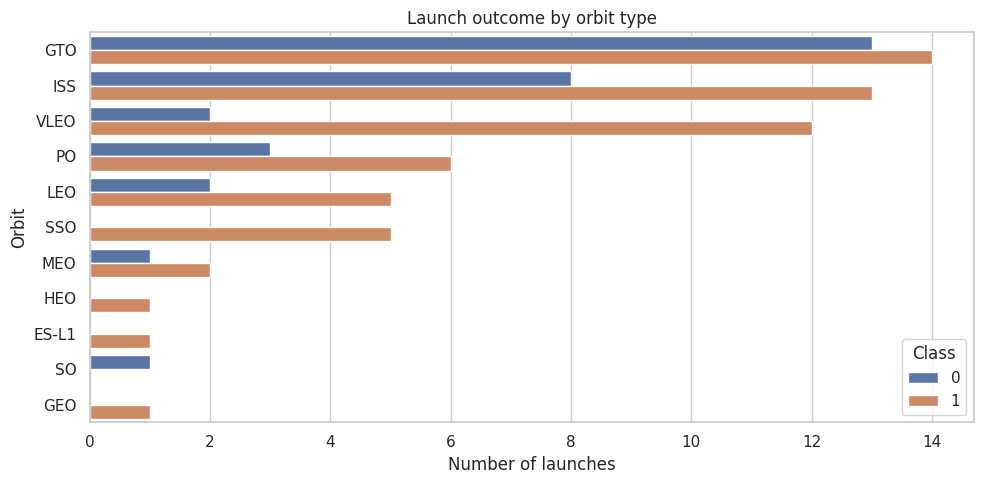

In [42]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, y="Orbit", hue="Class", order=df["Orbit"].value_counts().index, ax=ax)
ax.set(title="Launch outcome by orbit type", xlabel="Number of launches", ylabel="Orbit")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

## 7. Explore launch sites and outcomes

In [43]:
df["LaunchSite"].value_counts(dropna=False)

LaunchSite
CCAFS SLC 40    55
KSC LC 39A      22
VAFB SLC 4E     13
Name: count, dtype: int64

In [44]:
outcome_by_site = pd.crosstab(df["LaunchSite"], df["Class"], margins=True)
outcome_by_site

Class,0,1,All
LaunchSite,,,
CCAFS SLC 40,22,33,55
KSC LC 39A,5,17,22
VAFB SLC 4E,3,10,13
All,30,60,90


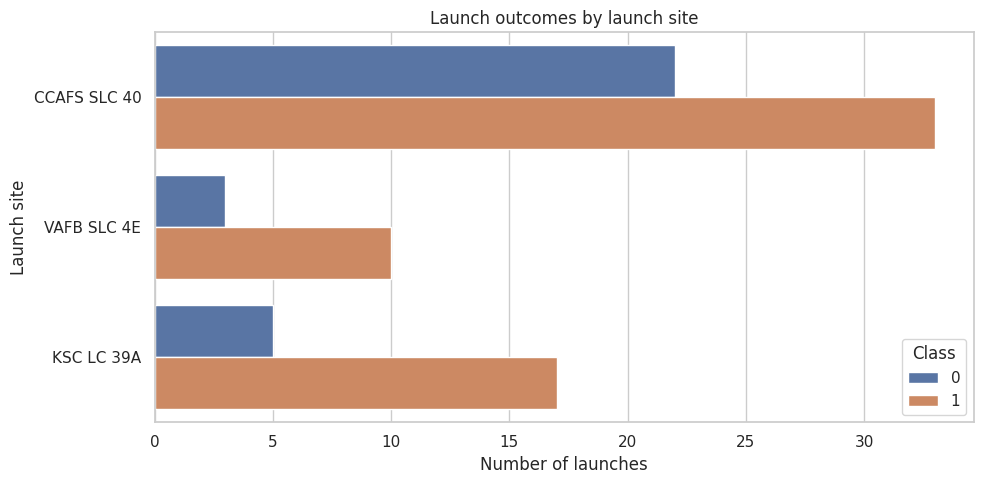

In [45]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=df, y="LaunchSite", hue="Class", ax=ax)
ax.set(title="Launch outcomes by launch site", xlabel="Number of launches", ylabel="Launch site")
ax.legend(title="Class")
plt.tight_layout()
plt.show()

In [46]:
if "Outcome" in df.columns:
    display(pd.crosstab(df["Outcome"], df["Class"], margins=True))
else:
    print("The dataset has no 'Outcome' column.")

Class,0,1,All
Outcome,,,
False ASDS,6,0,6
False Ocean,2,0,2
False RTLS,1,0,1
None ASDS,2,0,2
None None,19,0,19
True ASDS,0,41,41
True Ocean,0,5,5
True RTLS,0,14,14
All,30,60,90


## 8. Flight number and payload mass
The plots below compare flight number and payload mass against the launch class. They are exploratory: the visual patterns alone do not establish causation.

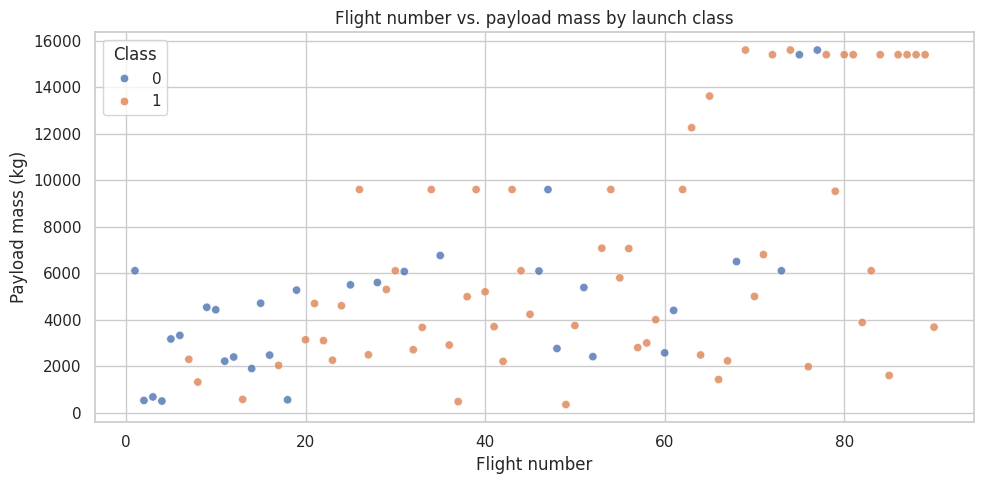

In [47]:
required = {"FlightNumber", "PayloadMass", "Class"}
missing_columns = required.difference(df.columns)
if missing_columns:
    print("Cannot create flight/payload plot; missing columns:", sorted(missing_columns))
else:
    fig, ax = plt.subplots(figsize=(10, 5))
    sns.scatterplot(data=df, x="FlightNumber", y="PayloadMass", hue="Class", alpha=0.8, ax=ax)
    ax.set(title="Flight number vs. payload mass by launch class",
           xlabel="Flight number", ylabel="Payload mass (kg)")
    plt.tight_layout()
    plt.show()

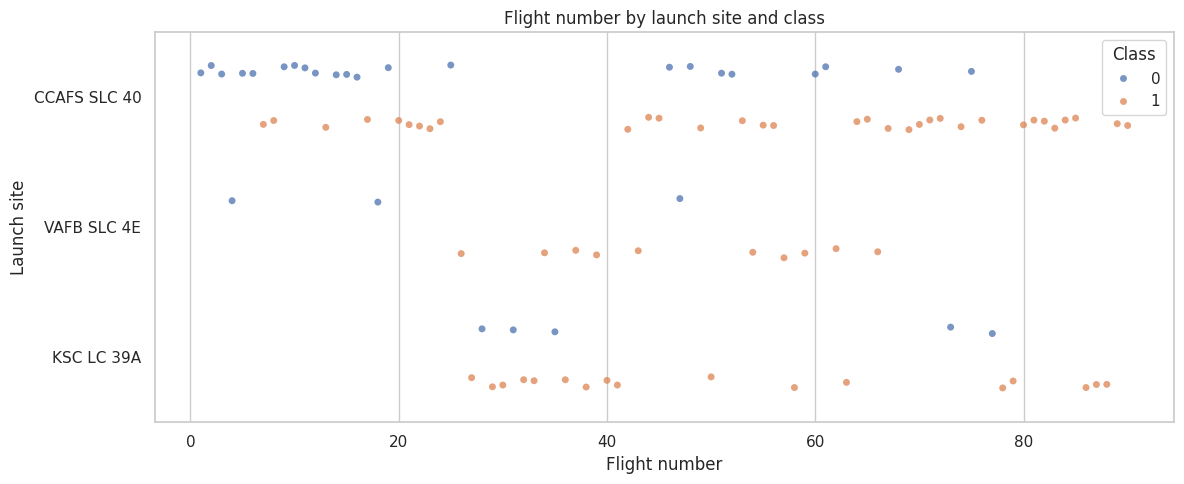

In [48]:
if {"FlightNumber", "LaunchSite", "Class"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.stripplot(data=df, x="FlightNumber", y="LaunchSite", hue="Class",
                  dodge=True, alpha=0.75, ax=ax)
    ax.set(title="Flight number by launch site and class",
           xlabel="Flight number", ylabel="Launch site")
    plt.tight_layout()
    plt.show()

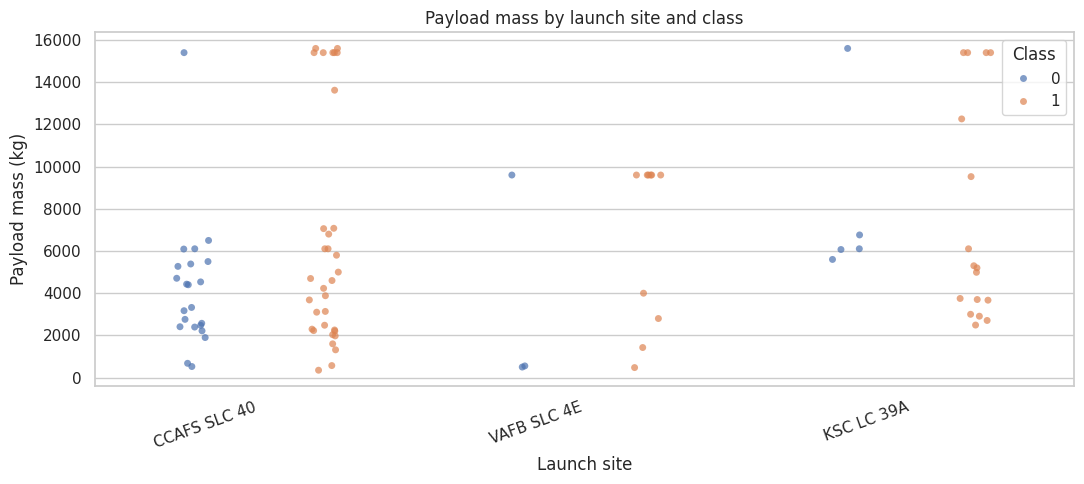

In [49]:
if {"LaunchSite", "PayloadMass", "Class"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(11, 5))
    sns.stripplot(data=df, x="LaunchSite", y="PayloadMass", hue="Class",
                  dodge=True, alpha=0.7, ax=ax)
    ax.set(title="Payload mass by launch site and class",
           xlabel="Launch site", ylabel="Payload mass (kg)")
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()

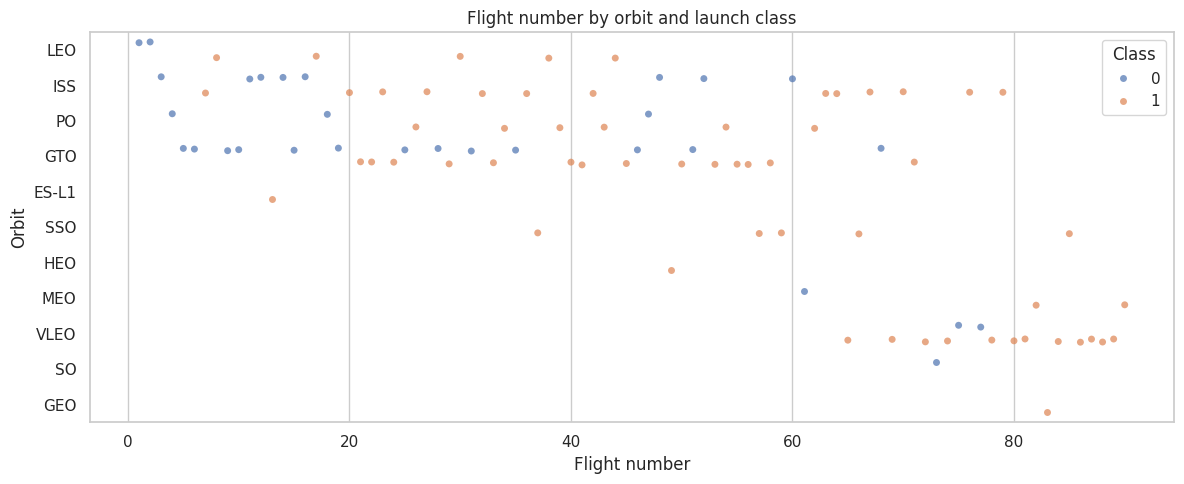

In [50]:
if {"FlightNumber", "Orbit", "Class"}.issubset(df.columns):
    fig, ax = plt.subplots(figsize=(12, 5))
    sns.stripplot(data=df, x="FlightNumber", y="Orbit", hue="Class",
                  dodge=True, alpha=0.7, ax=ax)
    ax.set(title="Flight number by orbit and launch class",
           xlabel="Flight number", ylabel="Orbit")
    plt.tight_layout()
    plt.show()

## 9. Inspect additional launch and booster features
These categorical summaries preserve the spirit of the original course notebook while handling columns that may be absent in another dataset version.

In [51]:
candidate_columns = [
    "Flights", "GridFins", "Reused", "Legs", "LandingPad",
    "Block", "ReusedCount", "Serial"
]
available_columns = [column for column in candidate_columns if column in df.columns]

for column in available_columns:
    print(f"\\n--- {column} ---")
    display(df[column].value_counts(dropna=False).head(20).to_frame("count"))

\n--- Flights ---


,count
Flights,
1,53
2,19
3,8
4,6
5,2
6,2


\n--- GridFins ---


,count
GridFins,
True,70
False,20


\n--- Reused ---


...

,count
Block,
5.0,39
1.0,19
3.0,15
4.0,11
2.0,6


\n--- ReusedCount ---


,count
ReusedCount,
0,30
1,24
3,12
5,11
2,9
4,4


\n--- Serial ---


,count
Serial,
B1049,6
B1051,5
B1046,4
B1048,4
B1059,4
B1056,4
B1047,3
B1058,3
B1060,3


## 10. Correlation of numeric features (optional)
Correlation is only calculated for numeric columns. It may reveal associations, but it does not show that one variable causes another.

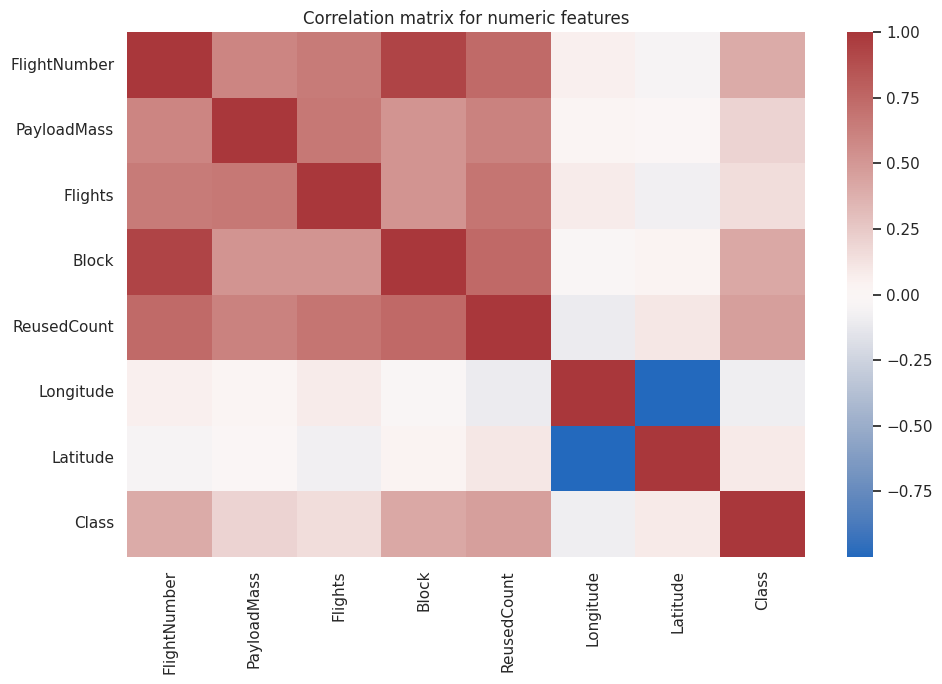

In [52]:
numeric_df = df.select_dtypes(include="number")
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(corr, cmap="vlag", center=0, annot=False, ax=ax)
    ax.set_title("Correlation matrix for numeric features")
    plt.tight_layout()
    plt.show()
else:
    print("Not enough numeric columns for a correlation matrix.")

## 11. Key takeaways

After running the notebook, summarize your observations here:

1. **Dataset quality:** Which columns have missing values or unexpected types?
2. **Payload mass:** Is the distribution symmetric or skewed? Are there unusual values?
3. **Orbit:** Which orbit categories appear most often? Do observed launch outcomes vary by orbit?
4. **Launch site:** Which sites have the most records, and how do outcomes differ across sites?
5. **Flight number:** Do later flights appear to have a different success pattern in this dataset?
6. **Limitations:** What other variables or additional data would be needed before making stronger claims?

Do not write conclusions before inspecting the actual outputs. Results may differ if the dataset version changes.

## 12. Practice exercises

1. Calculate the success rate (`Class == 1`) for each launch site.
2. Calculate the success rate for each orbit. Include the number of launches so small groups are not over-interpreted.
3. Compare payload-mass distributions for successful and unsuccessful launches.
4. Choose one additional feature and visualize how it relates to `Class`.
5. Write a short conclusion supported by at least two tables or plots.

### Example: success rate by launch site

In [53]:
if {"LaunchSite", "Class"}.issubset(df.columns):
    success_rate_by_site = (
        df.assign(success=(df["Class"] == 1))
          .groupby("LaunchSite", dropna=False)
          .agg(
              launches=("success", "size"),
              successful_launches=("success", "sum"),
              success_rate=("success", "mean"),
          )
          .sort_values("success_rate", ascending=False)
    )
    success_rate_by_site["success_rate"] = success_rate_by_site["success_rate"].mul(100).round(1)
    success_rate_by_site.rename(columns={"success_rate": "success_rate_percent"})
else:
    print("Required columns are not available.")

---
**Notebook:** `01_spacex_data_exploration.ipynb`  
**Dataset:** `data/raw/dataset_falcon9.csv`  
**Libraries:** pandas, Matplotlib, Seaborn

Before publishing, run all cells from top to bottom and review the generated plots and written conclusions.